# Practical Class Work - 3

## Title: Loan Approval Risk Mode

### 0) Notebook Setup, required libraries:

In [70]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import sklearn 

### 1) Data Loading and Business Understanding

In [71]:
# there's no column names in the dataset, so we have to specify them 
# from word file german.doc I took the column names and put them in a list

columns = [
    "checking_status", "duration_months", "credit_history", "purpose",
    "credit_amount", "savings", "employment_since", "installment_rate",
    "personal_status_sex", "other_debtors", "residence_since", "property",
    "age", "other_installment_plans", "housing", "existing_credits",
    "job", "people_liable", "telephone", "foreign_worker", "target"
]

#### Task 1.1 Load dataset

In [72]:
df = pd.read_csv("./dataset/german.data", sep=r"\s+", header=None, names=columns)

In [73]:
# # A bank wants to reduce losses. For each applicant, we must predict:
# ● Bad risk (1) vs Good risk (0)
# and produce a simple business decision recommendation.

df["target"] = df["target"].map({1: 0, 2: 1}) 


In [74]:
print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nFirst 5 rows of the dataset:")
display(df.head()) 

Shape: (1000, 21)
Rows: 1000
Columns: 21

First 5 rows of the dataset:


,checking_status,duration_months,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


In [75]:
print(df['target'].value_counts())
print(df['target'].value_counts(normalize=True))

target
0    700
1    300
Name: count, dtype: int64
target
0    0.7
1    0.3
Name: proportion, dtype: float64


#### Task 1.2 — Business interpretation

### Business Interpretation

1. A **default** is a client who fails to repay a loan on time or at all, so the bank loses part(or all) money it lent. In this project, a bad risk is labeled **1** and a good risk is labeled **0**.
2. A **false negative (FN)** means approving a client who is actually bad, so the bank loses the loan principal. A **false positive (FP)** means rejecting a client who is actually good, so the bank only loses the interest income it would have earned. A defaulted loan usually costs far more than the lost profit from one rejected client. The dataset's cost matrix says an FN costs **5 times more** than an FP. The data is imbalanced (70% good, 30% bad), so accuracy alone is misleading, and we must pay special attention to **Recall on the bad class**. The goal is not only a high accuracy, but a model and threshold that reduce costly FN errors without rejecting too many good clients.

### 2) Data Quality and Simple EDA

#### Task 2.1 Missing values & data types

In [76]:
print("Missing values:")
print(df.isnull().sum(),'\n')


Missing values:
checking_status            0
duration_months            0
credit_history             0
purpose                    0
credit_amount              0
savings                    0
employment_since           0
installment_rate           0
personal_status_sex        0
other_debtors              0
residence_since            0
property                   0
age                        0
other_installment_plans    0
housing                    0
existing_credits           0
job                        0
people_liable              0
telephone                  0
foreign_worker             0
target                     0
dtype: int64 



In [77]:
print("Data Types:")
print(df.dtypes)

Data Types:
checking_status              str
duration_months            int64
credit_history               str
purpose                      str
credit_amount              int64
savings                      str
employment_since             str
installment_rate           int64
personal_status_sex          str
other_debtors                str
residence_since            int64
property                     str
age                        int64
other_installment_plans      str
housing                      str
existing_credits           int64
job                          str
people_liable              int64
telephone                    str
foreign_worker               str
target                     int64
dtype: object


In [78]:
numeric_features = df.select_dtypes(include="number").columns.drop("target").tolist()
# print(numeric_features)
categorical_features = df.select_dtypes(exclude="number").columns.tolist()
# print(categorical_features)

In [79]:
print("Numerical features: ", numeric_features)
print(len(numeric_features))
print("Categorical features: ", categorical_features)
print(len(categorical_features))

Numerical features:  ['duration_months', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'people_liable']
7
Categorical features:  ['checking_status', 'credit_history', 'purpose', 'savings', 'employment_since', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']
13


#### Task 2.2 Correlation

In [80]:
corr_matrix = df.select_dtypes(include="number").corr()
display(corr_matrix.round(3))

,duration_months,credit_amount,installment_rate,residence_since,age,existing_credits,people_liable,target
duration_months,1.000,0.625,0.075,0.034,-0.036,-0.011,-0.024,0.215
credit_amount,0.625,1.000,-0.271,0.029,0.033,0.021,0.017,0.155
installment_rate,0.075,-0.271,1.000,0.049,0.058,0.022,-0.071,0.072
residence_since,0.034,0.029,0.049,1.000,0.266,0.090,0.043,0.003
age,-0.036,0.033,0.058,0.266,1.000,0.149,0.118,-0.091
existing_credits,-0.011,0.021,0.022,0.090,0.149,1.000,0.110,-0.046
people_liable,-0.024,0.017,-0.071,0.043,0.118,0.110,1.000,-0.003
target,0.215,0.155,0.072,0.003,-0.091,-0.046,-0.003,1.000


In [81]:
target_corr=corr_matrix["target"].drop("target")
print(target_corr.round(3))

duration_months     0.215
credit_amount       0.155
installment_rate    0.072
residence_since     0.003
age                -0.091
existing_credits   -0.046
people_liable      -0.003
Name: target, dtype: float64


In [82]:
top3 = target_corr.abs().sort_values(ascending=False).head(3)
print(top3.round(3))
print(target_corr[top3.index].round(3))

duration_months    0.215
credit_amount      0.155
age                0.091
Name: target, dtype: float64
duration_months    0.215
credit_amount      0.155
age               -0.091
Name: target, dtype: float64


### 3) Preprocessing

#### Task 3.1 Split train/test

In [83]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

In [84]:
X = df.drop(columns="target")
y = df["target"]

In [85]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42, stratify = y
)

In [86]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 20)
(200, 20)
(800,)
(200,)


In [87]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

target
0    0.7
1    0.3
Name: proportion, dtype: float64
target
0    0.7
1    0.3
Name: proportion, dtype: float64


#### Task 3.2 Prepare pipeline

In [88]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

In [89]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(X_train_processed.shape)
print(X_test_processed.shape,"\n")
print(len(preprocessor.named_transformers_["cat"].get_feature_names_out()))
print(preprocessor.get_feature_names_out()[:10])


(800, 61)
(200, 61) 

54
['num__duration_months' 'num__credit_amount' 'num__installment_rate'
 'num__residence_since' 'num__age' 'num__existing_credits'
 'num__people_liable' 'cat__checking_status_A11'
 'cat__checking_status_A12' 'cat__checking_status_A13']


### 4) Build 3 Baseline Models (No Tuning)

#### Task 4.1 Train models

In [90]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

In [91]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "kNN": KNeighborsClassifier(),
}

In [92]:
pipelines = {}
for name, model in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe

print(list(pipelines.keys()))

['Logistic Regression', 'Decision Tree', 'kNN']


#### Task 4.2 Evaluate models

In [93]:
results = []
for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })
    print(name)
    print(cm)
    print()

results_df = pd.DataFrame(results).set_index("Model")
print(results_df.round(3))

Logistic Regression
[[124  16]
 [ 28  32]]

Decision Tree
[[104  36]
 [ 38  22]]

kNN
[[124  16]
 [ 39  21]]

                     Accuracy  Precision  Recall     F1   TN  FP  FN  TP
Model                                                                   
Logistic Regression     0.780      0.667   0.533  0.593  124  16  28  32
Decision Tree           0.630      0.379   0.367  0.373  104  36  38  22
kNN                     0.725      0.568   0.350  0.433  124  16  39  21


**In credit risk, which is worse: approving a bad client (FN) or rejecting a good one (FP)? Explain.**

FN vs FP in credit risk

**Approving a bad client (False Negative) is worse than rejecting a good client (False Positive).**

- **FN (bad client approved):** the bank may lose the whole loan amount (the principal), plus collection and legal costs. A single default can wipe out the profit of many good loans.
- **FP (good client rejected):** the bank loses only the interest income it could have earned from that client, and the client may go to a competitor. The loss is real but limited.
- The dataset's own cost matrix says that an FN costs **5 times more** than an FP.
- In our test set, the best model (Logistic Regression) made **28 FN and 16 FP**. Using the cost matrix, its total cost is 28 × 5 + 16 × 1 = **156**, compared with 226 for the Decision Tree and 211 for kNN.
- Because FN is so expensive, Recall for the bad class matters more than overall accuracy. This motivates lowering the decision threshold in the next step.

### 5) Simple “Business Threshold”

In [94]:
log_reg_pipeline = pipelines["Logistic Regression"]
bad_probability = log_reg_pipeline.predict_proba(X_test)[:, 1]

print(bad_probability[:5].round(3))
print("Min probability:", bad_probability.min().round(3))
print("Max probability:", bad_probability.max().round(3))

[0.227 0.101 0.619 0.493 0.15 ]
Min probability: 0.007
Max probability: 0.911


In [95]:
thresholds = [0.65, 0.50, 0.35]

threshold_results = []
for t in thresholds:
    y_pred_t = (bad_probability >= t).astype(int)
    cm_t = confusion_matrix(y_test, y_pred_t)
    tn, fp, fn, tp = cm_t.ravel()
    threshold_results.append({
        "Threshold": t,
        "Precision": precision_score(y_test, y_pred_t),
        "Recall": recall_score(y_test, y_pred_t),
        "F1": f1_score(y_test, y_pred_t),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Rejected": fp + tp,
        "Approved": tn + fn,
        "Cost": fn * 5 + fp * 1,
    })
    print("Threshold:", t)
    print(cm_t)
    print()

threshold_df = pd.DataFrame(threshold_results).set_index("Threshold")
print(threshold_df.round(3))

Threshold: 0.65
[[133   7]
 [ 38  22]]

Threshold: 0.5
[[124  16]
 [ 28  32]]

Threshold: 0.35
[[109  31]
 [ 14  46]]

           Precision  Recall     F1   TN  FP  FN  TP  Rejected  Approved  Cost
Threshold                                                                     
0.65           0.759   0.367  0.494  133   7  38  22        29       171   197
0.50           0.667   0.533  0.593  124  16  28  32        48       152   156
0.35           0.597   0.767  0.672  109  31  14  46        77       123   101



**Which threshold you recommend and why?**
I recommend 0.35. It has the best F1 (0.672) and the lowest total cost under the dataset's cost matrix (101, versus 156 at 0.50 and 197 at 0.65). It cuts the number of bad clients approved by half compared with the default threshold.

**How does lowering the threshold change the number of rejected clients?**
Lowering the threshold increases the number of rejected clients. At 0.65 the bank rejects 29 applicants (14.5%), at 0.50 it rejects 48 (24%), and at 0.35 it rejects 77 (38.5%). A lower bar means more applicants are flagged as risky.

**Which threshold reduces the number of bad clients approved?**
Threshold 0.35. It lets only 14 bad clients through (FN = 14), compared with 28 at 0.50 and 38 at 0.65. It also has the highest Recall (76.7%).

**Which threshold increases the number of good clients rejected?**
Threshold 0.35 again. It wrongly rejects 31 good clients (FP = 31), compared with 16 at 0.50 and only 7 at 0.65. This is the price of catching more bad clients.

**If I were the Head of Risk:**
I would choose 0.35 because one bad loan costs about five times more than one lost good client. Moving from 0.50 to 0.35 saves 14 defaults (14 x 5 = 70 cost units) and loses 15 more good clients (15 x 1 = 15 cost units), a net improvement of 55. 

### 6) Production-Oriented task: “Manual Review Queue”

#### Task 6.1 Create 3 decision zones using probability

In [96]:
conditions = [
    bad_probability < 0.20,
    (bad_probability >= 0.20) & (bad_probability <= 0.50),
    bad_probability > 0.50,
]
zone_labels = ["Auto-approve", "Manual review", "Auto-reject"]

decision_zone = np.select(conditions, zone_labels, default="Unassigned")

In [97]:
zone_counts = pd.Series(decision_zone).value_counts().reindex(zone_labels)
print(zone_counts)
print((zone_counts / len(decision_zone) * 100).round(1))

Auto-approve     91
Manual review    61
Auto-reject      48
Name: count, dtype: int64
Auto-approve     45.5
Manual review    30.5
Auto-reject      24.0
Name: count, dtype: float64


In [98]:
zone_table = pd.DataFrame({
    "probability": bad_probability,
    "zone": decision_zone,
    "actual_bad": y_test.values,
})

zone_summary = zone_table.groupby("zone").agg(
    applications=("actual_bad", "size"),
    actual_bad=("actual_bad", "sum"),
    bad_rate=("actual_bad", "mean"),
).reindex(zone_labels)
zone_summary["actual_good"] = zone_summary["applications"] - zone_summary["actual_bad"]
print(zone_summary.round(3))

               applications  actual_bad  bad_rate  actual_good
zone                                                          
Auto-approve             91          10     0.110           81
Manual review            61          18     0.295           43
Auto-reject              48          32     0.667           16



**Counts on the test set (200 applications):**
- Auto-approve (p < 0.20): **91** applications (45.5%)
- Manual review (0.20 <= p <= 0.50): **61** applications (30.5%)
- Auto-reject (p > 0.50): **48** applications (24.0%)

**How this reduces workload:**
Without a model, an officer would have to read all 200 applications. With three zones, 139 of 200 (69.5%) are decided automatically, and staff only review 61 (30.5%), so the workload drops by about two thirds. Staff time goes to the cases where human judgement adds the most value.

**How this reduces risk:**
The automatically approved group is low risk: only 10 of 91 (11%) are bad clients, compared with 30% in the whole sample. With a single 0.50 threshold, 28 bad clients would be approved without any check. With the queue, only 10 bad clients are approved automatically, and the other 18 bad clients in the middle zone get a human look before any money is lent. Good clients in the middle zone also get a fair second chance instead of being rejected by a fixed rule.


### 7) Business Demonstration

## <p align = 'center'> Business Demo: Loan Approval Risk Model</p>

## 1. Executive summary

- **Dataset:** the German Credit dataset, with 1000 past loan applicants described by 20 features (loan amount, duration, checking and savings status, credit history, age, and others). 30% of the applicants are bad risks and 70% are good risks.
- **Goal:** predict for each new applicant whether they are a bad risk (1) or a good risk (0), so the bank can reduce losses from defaults. Approving a bad client costs about 5 times more than rejecting a good one.
- **Best model:** Logistic Regression. It beat the Decision Tree and kNN on Accuracy, Recall and F1, and it outputs probabilities that we can use for business rules.
- **Key result:** at the default threshold (0.50) it reaches Accuracy 0.78 and Recall 0.53 for bad clients. At the recommended threshold (0.35) it catches 46 of 60 bad clients (Recall 0.77), with F1 0.67 and Precision 0.60.
- **Recommended threshold:** 0.35. It has the best F1 and the lowest cost under the cost matrix (101, versus 156 at 0.50 and 197 at 0.65). Only 14 bad clients are approved, versus 28 at 0.50. The price is more rejected good clients (31, versus 16).
- **Manual review queue:** applicants with a bad-risk probability below 0.20 are approved automatically (91 of 200), those above 0.50 are rejected automatically (48 of 200), and the 61 cases in between go to a loan officer. The 0.35 cut-off lies inside the review zone, so it can guide the reviewer's decision. About 70% of cases are decided without human work, and the automatic approvals have a bad rate of only 11%.



In [99]:
# for 2 item
from sklearn.metrics import ConfusionMatrixDisplay

model_comments = pd.Series({
    "Logistic Regression": "Best on every metric and gives probabilities for thresholds.",
    "Decision Tree": "Overfits and performs below the always-approve baseline.",
    "kNN": "Decent accuracy but misses most of the bad clients.",
})

comparison_table = results_df[["Accuracy", "Recall", "F1"]].copy()
comparison_table.columns = ["Accuracy", "Recall (bad class)", "F1"]
comparison_table["Comment"] = model_comments
print(comparison_table.round(3).to_string())

                     Accuracy  Recall (bad class)     F1                                                       Comment
Model                                                                                                                 
Logistic Regression     0.780               0.533  0.593  Best on every metric and gives probabilities for thresholds.
Decision Tree           0.630               0.367  0.373      Overfits and performs below the always-approve baseline.
kNN                     0.725               0.350  0.433           Decent accuracy but misses most of the bad clients.


## 2. Model comparison

| Model | Accuracy | Recall (bad class) | F1 | Comment |
|---|---|---|---|---|
| Logistic Regression | 0.780 | 0.533 | 0.593 | Best on every metric and gives probabilities for thresholds. |
| Decision Tree | 0.630 | 0.367 | 0.373 | Overfits and performs below the always-approve baseline. |
| kNN | 0.725 | 0.350 | 0.433 | Decent accuracy but misses most of the bad clients. |

All values are on the 200-applicant test set at threshold 0.50.

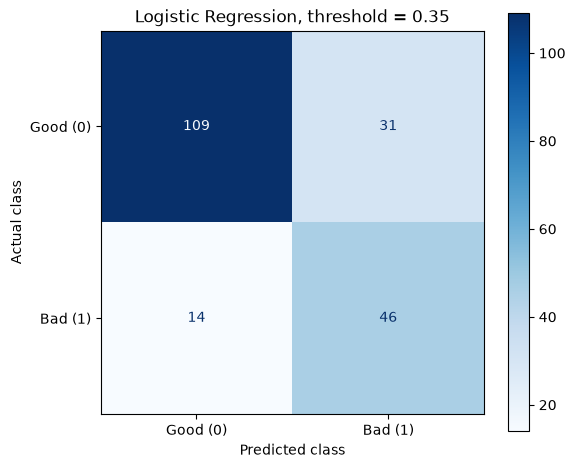

In [100]:
# for 3 item
final_threshold = 0.35
y_pred_final = (bad_probability >= final_threshold).astype(int)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    display_labels=["Good (0)", "Bad (1)"],
    cmap="Blues",
    values_format="d",
    ax=ax,
)
ax.set_title("Logistic Regression, threshold = 0.35")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
plt.tight_layout()
plt.show()

## 3. Visual

The confusion matrix of the Logistic Regression model at threshold 0.35 is shown in the plot above (109 good approved, 31 good rejected, 14 bad approved, 46 bad rejected).

In [101]:
# for 4 item
X_test_reset = X_test.reset_index(drop=True)
example_positions = [zone_table.index[zone_table["zone"] == z][0] for z in zone_labels]

example_view = X_test_reset.loc[
    example_positions,
    ["duration_months", "credit_amount", "age", "checking_status", "savings", "credit_history"],
].copy()
example_view["bad_probability"] = bad_probability[example_positions].round(3)
example_view["zone"] = decision_zone[example_positions]
example_view["actual_outcome"] = y_test.values[example_positions]
example_view["actual_outcome"] = example_view["actual_outcome"].map({0: "Good", 1: "Bad"})
print(example_view.to_string())

   duration_months  credit_amount  age checking_status savings credit_history  bad_probability           zone actual_outcome
1               12           1860   34             A12     A61            A34            0.101   Auto-approve           Good
0               18           1913   36             A12     A64            A32            0.227  Manual review           Good
2               24           1024   48             A11     A61            A33            0.619    Auto-reject            Bad


## 4. Example applicants

**Applicant A: 12-month loan of 1,860 DM, age 34 - probability 0.101 - AUTO-APPROVE**
This is a short, modest loan to a client with a positive checking balance. The model sees a low chance of default, so the system can approve it without staff time. (The client did turn out to be good.)

**Applicant B: 18-month loan of 1,913 DM, age 36 - probability 0.227 - MANUAL REVIEW**
This client has strong savings (1000 DM or more) and a clean repayment record, but the probability is just above the approval limit. A loan officer should check income and documents, and would most likely approve. (The client was in fact good.)

**Applicant C: 24-month loan of 1,024 DM, age 48 - probability 0.619 - AUTO-REJECT**
The client has a negative checking balance, almost no savings and a history of late payments. These are classic warning signs, so the system rejects the application. (The client did turn out to be bad.)